## Baseline training script

### Imports

In [6]:
import sys
from pathlib import Path

project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import lightning.pytorch as pl
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data import CLASS_NAMES, BloodDataModule

print(f"PyTorch:   {torch.__version__}")
print(f"Lightning: {pl.__version__}")
print(f"CUDA:      {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device:    {torch.cuda.get_device_name(0)}")

PyTorch:   2.14.1+cu126
Lightning: 2.6.6
CUDA:      True
Device:    NVIDIA GeForce RTX 3050 Laptop GPU


### Data initialisation

In [7]:
dm = BloodDataModule(batch_size=64, use_augmentations=True, grayscale=False, num_workers=0)
dm.setup()

print(f"Train samples: {len(dm.train_dataset):,}")
print(f"Val samples:   {len(dm.val_dataset):,}")
print(f"Test samples:  {len(dm.test_dataset):,}")
print(f"Channels:      {dm.in_channels}")
print(f"Train mean:    {np.round(dm.train_mean, 4)}")
print(f"Train std:     {np.round(dm.train_std, 4)}")

print("\nClass counts and weights (train):")
counts = dm.class_counts.numpy()
weights = dm.class_weights.numpy()
for idx, (name, c, w) in enumerate(zip(CLASS_NAMES, counts, weights)):
    print(f"  [{idx}] {name:<20}: count={c:5d} ({c / len(dm.train_dataset) * 100:5.2f}%), weight={w:.4f}")

Train samples: 11,959
Val samples:   1,712
Test samples:  3,421
Channels:      3
Train mean:    [0.8162 0.6685 0.6955]
Train std:     [0.2152 0.2415 0.1175]

Class counts and weights (train):
  [0] Basophil            : count=  852 ( 7.12%), weight=1.4975
  [1] Eosinophil          : count= 2181 (18.24%), weight=0.5850
  [2] Erythroblast        : count= 1085 ( 9.07%), weight=1.1759
  [3] Immature Granulocyte: count= 2026 (16.94%), weight=0.6298
  [4] Lymphocyte          : count=  849 ( 7.10%), weight=1.5028
  [5] Monocyte            : count=  993 ( 8.30%), weight=1.2849
  [6] Neutrophil          : count= 2330 (19.48%), weight=0.5476
  [7] Platelet            : count= 1643 (13.74%), weight=0.7766


In [8]:
batch_x, batch_y = next(iter(dm.train_dataloader()))

print(f"batch_x: shape={batch_x.shape}, dtype={batch_x.dtype}, range=[{batch_x.min():.2f}, {batch_x.max():.2f}]")
print(f"batch_y: shape={batch_y.shape}, dtype={batch_y.dtype}")
print(f"labels:  {batch_y[:10].tolist()}")

batch_x: shape=torch.Size([64, 3, 28, 28]), dtype=torch.float32, range=[-5.92, 2.59]
batch_y: shape=torch.Size([64]), dtype=torch.int64
labels:  [1, 7, 2, 2, 3, 4, 4, 5, 7, 7]


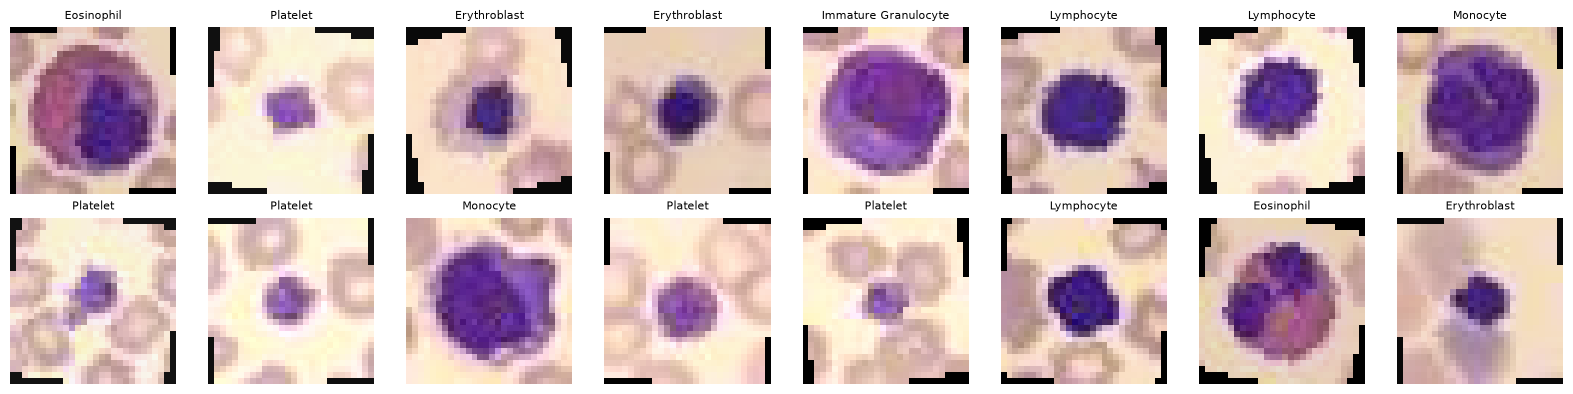

In [9]:
def denormalize(tensor, mean, std):
    img = tensor.clone().detach().cpu()
    mean_t = torch.tensor(mean).view(-1, 1, 1)
    std_t = torch.tensor(std).view(-1, 1, 1)
    img = img * std_t + mean_t
    return torch.clamp(img, 0.0, 1.0).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flatten()):
    img = denormalize(batch_x[i], dm.train_mean, dm.train_std)
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[batch_y[i]], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Model Architecture & Baseline Initialization 


In [10]:
from src.model import BloodClassifier, BloodNet

# Instantiate baseline model
model = BloodClassifier(
    in_channels=dm.in_channels,
    num_classes=dm.num_classes,
    base_channels=32,
    dropout=0.2,
    lr=1e-3,
    weight_decay=1e-4,
    optimizer_name="adamw",
    scheduler_name="cosine",
    max_epochs=20,
    class_weights=None,  # Unweighted baseline; weighted loss can be evaluated in HPO / ablations
)

print(model)

BloodClassifier(
  (net): BloodNet(
    (block1): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (block3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, st

In [11]:
# Compute and display model parameter counts
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters:     102,248
Trainable parameters: 102,248


In [12]:
# Verify forward pass on the sample batch from DataLoader
model.eval()
with torch.no_grad():
    sample_logits = model(batch_x)
    sample_preds = torch.argmax(sample_logits, dim=-1)
    sample_loss = model.loss_fn(sample_logits, batch_y)

print(f"Batch input shape:   {batch_x.shape}")
print(f"Logits output shape: {sample_logits.shape} (expected [{batch_x.shape[0]}, {dm.num_classes}])")
print(f"Sample initial loss: {sample_loss.item():.4f}")
print(f"Initial predictions: {sample_preds[:8].tolist()}")
print(f"Ground truth labels: {batch_y[:8].tolist()}")

Batch input shape:   torch.Size([64, 3, 28, 28])
Logits output shape: torch.Size([64, 8]) (expected [64, 8])
Sample initial loss: 2.0895
Initial predictions: [0, 0, 5, 0, 1, 0, 0, 1]
Ground truth labels: [1, 7, 2, 2, 3, 4, 4, 5]
